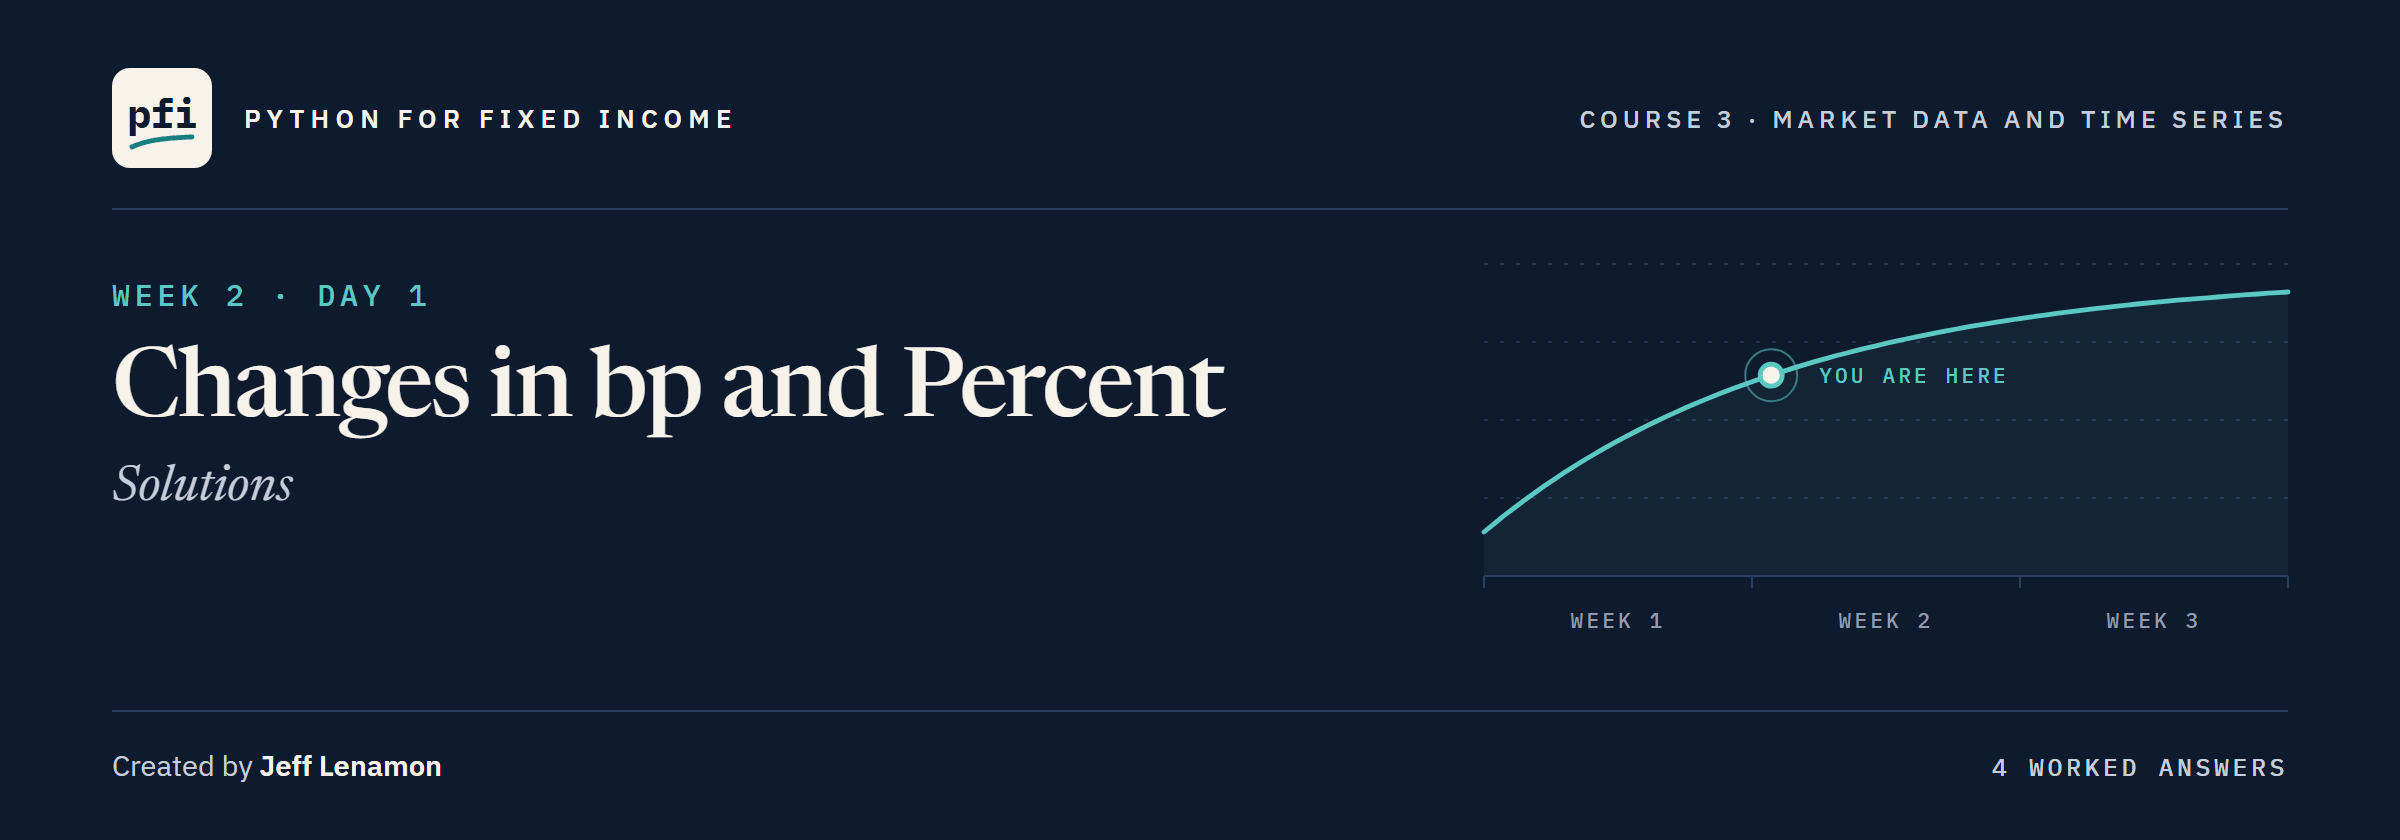

# Changes in bp and Percent: Solutions

Week 2, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day1/06_changes_in_bp_and_percent_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the two files and Excel's reference rows, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 06 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(6, after=6)

Work folder pfi_course3_06_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 06 left it, 6 commits, tagged week1


In [2]:
import importlib

import pandas as pd

import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
# each week's last row, labelled by its own date; one row back is one week back
weekly = md.last_per_period(treasury['2 Yr'], 'W-FRI')
september = md.change_bp(weekly).loc['2026-09']
print(september.round(1))
ex1_count = len(september)
ex1_largest = september.max()

date
2026-09-04     3.0
2026-09-11    26.0
2026-09-18    13.0
2026-09-25     5.0
Name: 2 Yr, dtype: float64


The week of Labor Day still compares Friday with Friday.

In [5]:
check('Exercise 1 the number of weeks', ex1_count, 4)
check('Exercise 1 the largest weekly change', ex1_largest, 25.99999999999998)

Exercise 1 the number of weeks: correct
Exercise 1 the largest weekly change: correct


### Exercise 2

In [6]:
as_of = pd.Timestamp('2026-10-02')
# the last day of September: the first of October, less one day
since = pd.Timestamp('2026-10-01') - pd.Timedelta(days=1)
ex2_ig = md.change_since_bp(spreads['ig_spread_bp'], as_of, since, percent_units=False)
ex2_hy = md.change_since_bp(spreads['hy_spread_bp'], as_of, since, percent_units=False)
print(f'Since {since:%Y-%m-%d}: IG {ex2_ig:+.1f} bp, HY {ex2_hy:+.1f} bp (synthetic)')

Since 2026-09-30: IG -1.8 bp, HY -6.0 bp (synthetic)


Had 30 September had no row, the as-of value would have stepped back with no change to the code.

In [7]:
check('Exercise 2 investment grade, month to date', ex2_ig, -1.7999999999999972)
check('Exercise 2 high yield, month to date', ex2_hy, -6.0)

Exercise 2 investment grade, month to date: correct
Exercise 2 high yield, month to date: correct


### Exercise 3

In [8]:
%%writefile -a marketdata.py


def yield_change_table(curve: pd.DataFrame, tenors: list[str], as_of) -> pd.DataFrame:
    """One row per tenor: the level and the 1-day, 1-week, and 1-month changes, all as of one date.

    Units: level_pct in percent (the curve's units); the three changes in bp. Convention: the level is the
    as-of value; the 1-day change is from the observation before the as-of row; the 1-week and 1-month
    changes use as-of values 7 calendar days and one calendar month back (change_since_bp). Each tenor's
    missing values are dropped first, so a tenor that starts late still works after its start.
    Raises ValueError if as_of is before a tenor's first observation.
    """
    as_of = pd.Timestamp(as_of)
    rows = {}
    for tenor in tenors:
        series = curve[tenor].dropna()
        # the as-of row and the row before it
        used, level = value_as_of(series, as_of)
        previous = series.index[series.index.get_loc(used) - 1]
        rows[tenor] = {
            "level_pct": level,
            "chg_1d_bp": change_since_bp(series, used, previous),
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7)),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1)),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_yield_change_table_known_date():
    curve = read_treasury()
    table = md.yield_change_table(curve, ["2 Yr", "10 Yr"], "2026-10-02")
    assert list(table.index) == ["2 Yr", "10 Yr"]
    assert table.loc["10 Yr", "level_pct"] == 5.28
    # the 1-day change is the last row of change_bp, the 1-month change Excel's reference value
    assert table.loc["10 Yr", "chg_1d_bp"] == pytest.approx(md.change_bp(curve["10 Yr"]).iloc[-1], abs=1e-9)
    assert table.loc["10 Yr", "chg_1m_bp"] == pytest.approx(read_reference().loc["2026-10-02", "chg1m_10y_bp"], abs=1e-9)

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................                                               [100%]
26 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
table = md.yield_change_table(treasury, ['2 Yr', '5 Yr', '10 Yr', '30 Yr'], '2026-10-02')
ex3_value = table.loc['30 Yr', 'chg_1m_bp']
table.round(2)

,level_pct,chg_1d_bp,chg_1w_bp,chg_1m_bp
2 Yr,4.83,5.0,2.0,44.0
5 Yr,5.06,5.0,8.0,52.0
10 Yr,5.28,4.0,11.0,49.0
30 Yr,5.63,2.0,14.0,36.0


`pd.DataFrame.from_dict(rows, orient='index')` makes each key a row, as `pd.DataFrame(rows).T` did in 6.5.

In [12]:
check('Exercise 3 the 30 Yr one-month change', ex3_value, 36.00000000000003)

Exercise 3 the 30 Yr one-month change: correct


### Exercise 4: AI check

The bug: `pct_change()` is the change as a share of the level, so times 100 it is a percent of the yield, labelled bp.
On 2026-10-02 it returns 0.7634 for a 4 bp move, and the docstring's last sentence forbids exactly that.
The fix: the difference from the previous row, times 100.

In [13]:
def daily_change_bp(series):
    """Daily change of a yield series, in basis points.

    Units: yields in percent in, bp out: (y_t - y_{t-1}) x 100, from the previous
    observation (row), whatever the calendar gap. The first value is NaN.
    Never a percent change of the yield level.
    """
    # the fix: the difference from the previous row, times 100, as =(B3-B2)*100
    return (series - series.shift(1)) * 100

In [14]:
# Excel's =(B3-B2)*100 on the 190 rows of 2026
ai_changes = daily_change_bp(treasury['10 Yr']).loc[reference.index]
ai_gap = (ai_changes - reference['chg_10y_bp']).abs().max()
assert ai_gap <= 1e-9, f"differs from Excel's daily change in bp by up to {ai_gap:.2f} bp"
print(f'Equal to Excel on all {len(reference)} rows of 2026: largest gap {ai_gap:.1e} bp')
ex4_last = daily_change_bp(treasury['10 Yr']).iloc[-1]

Equal to Excel on all 190 rows of 2026: largest gap 0.0e+00 bp


Keep the test: the bug cannot come back unnoticed.

In [15]:
check('Exercise 4 the last daily change', ex4_last, 4.0000000000000036)

Exercise 4 the last daily change: correct


[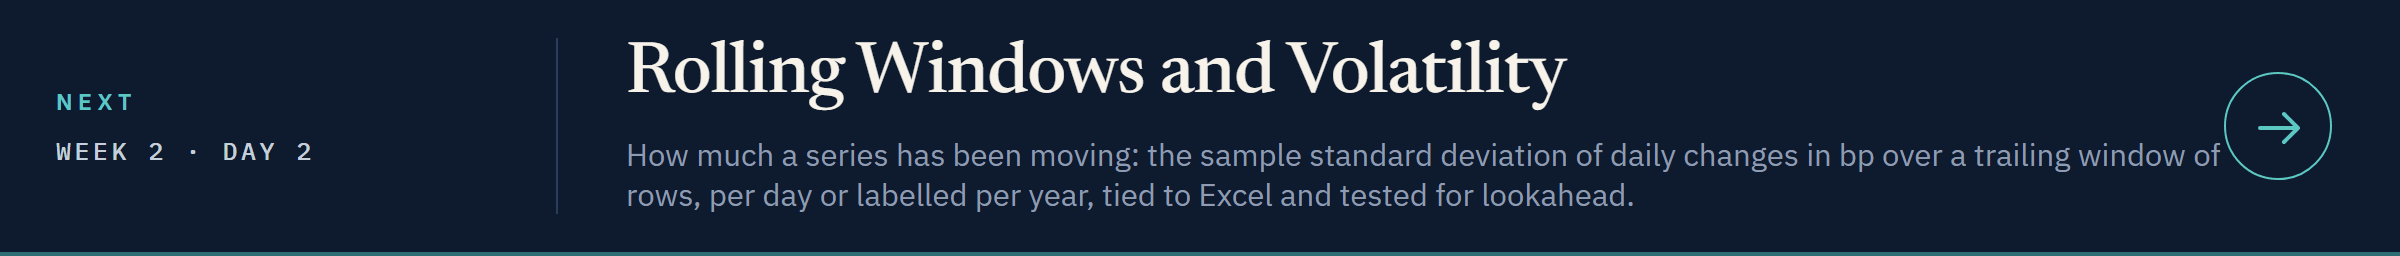](../day2/07_rolling_windows_and_volatility.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day2/07_rolling_windows_and_volatility.ipynb)